## MIS780 Advanced AI For Business - Assessment 1 - T2 2025

**Student Name:** Ully Sai Vishnu

**Student ID:** s224021805


## Table of Content

1. [Executive Summary](#cell_executivesummary)


2. [Data Exploration](#cell_exploration)


3. [Sentiment Analysis](#cell_sentiment)


4. [Topic Modeling](#cell_TopicModeling)


5. [Practical Implication](#cell_PracticalImplication)


<a id = "cell_executivesummary"></a>
### 1. Executive Summary


Airlines today compete not just on price, but on passenger experience. This analysis addresses a key business challenge: which airlines deliver the most consistent quality, and why others lag. Using ratings, sentiment analysis, and topic modeling on passenger reviews, we uncover gaps in service, food, and entertainment across cabin classes. Our findings help identify opportunities for experience improvement, especially for carriers like Qantas and Jetstar, and offer data-driven recommendations to enhance customer satisfaction and loyalty.


<a id = "cell_exploration"></a>
### 2. Data Exploration




In [2]:
!pip install gensim

Session needs to restart after installing gensim

In [3]:
#Loading all the necessary libraries for analysis

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.tokenize import RegexpTokenizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk
import gensim
from gensim import corpora
from gensim.models import LdaModel
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from gensim import corpora
from gensim.models import LdaModel
from wordcloud import WordCloud
from gensim.models import CoherenceModel
from gensim.utils import simple_preprocess
from gensim.parsing.preprocessing import STOPWORDS
from nltk.corpus import stopwords

nltk.download('punkt')         # To break sentences into words
nltk.download('wordnet')       # Lemmatizing
nltk.download('vader_lexicon') # for sentiment analysis
nltk.download('punkt_tab')     # Added to fix the LookupError
nltk.download('stopwords')

# Load data
df = pd.read_csv('A1_dataset.csv')

# Sample 50,000 records with seed
seed = 224021805
IQ_df = df.sample(n=50000, random_state=seed)

# Clean text
def clean_text(text):
    text = str(text)
    text = re.sub(r'<.*?>', ' ', text)               # remove HTML tags
    text = re.sub(r'http\S+|www.\S+', ' ', text)     # remove URLs
    text = re.sub(r'[^A-Za-z\s]', ' ', text)         # remove numbers/symbols
    text = re.sub(r'\s+', ' ', text)                 # normalize spaces
    return text.lower().strip()

# Combine and clean title + review
IQ_df['Combined_text'] = IQ_df['Title'].fillna('') + ' ' + IQ_df['Review'].fillna('')
IQ_df['Cleaned_Review'] = IQ_df['Combined_text'].apply(clean_text)

# Tokenize, remove stopwords, lemmatize
STOPWORDS = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_and_lemmatize(text):
    tokens = simple_preprocess(str(text), deacc=True)  # tokenize, remove punctuation
    tokens_nostop = [t for t in tokens if t not in STOPWORDS and len(t) > 2]
    lemmatized = [lemmatizer.lemmatize(t) for t in tokens_nostop]  # default lemmatization
    return lemmatized

IQ_df['Final_Review'] = IQ_df['Cleaned_Review'].apply(preprocess_and_lemmatize)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


To ensure high-quality insights from customer reviews, we performed advanced text cleaning and preparation. This involved removing irrelevant characters **(HTML tags, links, symbols)**, eliminating common filler words, and standardizing words to their base form using **lemmatization**. These steps help reduce noise and improve the accuracy of topic modeling and sentiment analysis. The processed reviews now serve as a reliable foundation for understanding customer concerns, interests, and satisfaction trends across airlines.

### Q1: Top 10 Airlines by Overall Ratings – Service Category Consistency & Qantas/Jetstar Recommendation Analysis

In [6]:
MIN_REVIEWS = 30

#  Top 10 by Overall Rating
rating_summary = (
    IQ_df.groupby(['AirlineName', 'CabinType'])
    .agg(avg_overall_rating=('OverallScore', 'mean'),
         review_count=('OverallScore', 'count'))
    .reset_index()
)


filtered_ratings = rating_summary[rating_summary['review_count'] >= MIN_REVIEWS]

top10_overall = (
    filtered_ratings.sort_values(['CabinType', 'avg_overall_rating'], ascending=[True, False])
    .groupby('CabinType')
    .head(10)
    .copy()
)

top10_overall['Rank'] = top10_overall.groupby('CabinType').cumcount() + 1
top10_overall = top10_overall[['Rank', 'AirlineName', 'CabinType', 'avg_overall_rating', 'review_count']]
display(top10_overall)

#  Rank by other service metrics
def get_top10_by_service(service_col):
    top_service = (
        IQ_df.groupby(['AirlineName', 'CabinType'])[service_col]
        .mean()
        .reset_index()
        .sort_values(['CabinType', service_col], ascending=[True, False])
        .groupby('CabinType')
        .head(10)
        .copy()
    )
    top_service['Rank'] = top_service.groupby('CabinType').cumcount() + 1
    return top_service[['Rank', 'AirlineName', 'CabinType', service_col]]

# Top 10 by Food Rating
top10_food = get_top10_by_service('FoodRating')
print(" Top 10 by Food Rating")
display(top10_food)

# Top 10 by Ground Service Rating
top10_ground = get_top10_by_service('GroundServiceRating')
print(" Top 10 by Ground Service Rating")
display(top10_ground)

# Top 10 by Entertainment Rating
top10_entertainment = get_top10_by_service('EntertainmentRating')
print(" Top 10 by Entertainment Rating")
display(top10_entertainment)


# Recommendation Score (Top 10 & Bottom 10)


# Converting 'Recommended' to numeric (1 for yes, 0 for no)
IQ_df['Recommended_numeric'] = (
    IQ_df['Recommended']
    .astype(str)
    .str.lower()
    .map({'yes': 1, 'no': 0})
    .fillna(0)
)

# Group by airline and cabin type, compute average recommendation
rec_summary = (
    IQ_df
    .groupby(['AirlineName', 'CabinType'])['Recommended_numeric']
    .mean()
    .reset_index()
)

# Sort airlines by recommendation score (highest first)
rec_sorted = rec_summary.sort_values(by='Recommended_numeric', ascending=False)
# Convert to numeric
# Check full recommendation rankings for Qantas and Jetstar
qj_rankings = rec_sorted[rec_sorted['AirlineName'].isin(['Qantas Airways', 'Jetstar Airways'])].copy()




# Add CabinType-specific ranks
rec_sorted['Cabin_Rank'] = (
    rec_sorted
    .sort_values(['CabinType', 'Recommended_numeric'], ascending=[True, False])
    .groupby('CabinType')
    .cumcount() + 1
)



,Rank,AirlineName,CabinType,avg_overall_rating,review_count
106,1,Hainan Airlines,Business Class,8.852941,68
76,2,EVA Air,Business Class,8.771930,57
68,3,China Southern Airlines,Business Class,8.599278,277
100,4,Garuda Indonesia,Business Class,8.318584,113
2,5,Aegean Airlines,Business Class,7.826087,46
0,6,ANA All Nippon Airways,Business Class,7.767442,43
153,7,Qatar Airways,Business Class,7.754967,453
64,8,China Airlines,Business Class,7.378378,37
169,9,Singapore Airlines,Business Class,7.363636,165
62,10,Cathay Pacific Airways,Business Class,7.357143,168


 Top 10 by Food Rating


,Rank,AirlineName,CabinType,FoodRating
225,1,airBaltic,Business Class,4.750000
106,2,Hainan Airlines,Business Class,4.544118
76,3,EVA Air,Business Class,4.385965
28,4,Air Serbia,Business Class,4.285714
222,5,WestJet Airlines,Business Class,4.250000
68,6,China Southern Airlines,Business Class,4.249097
100,7,Garuda Indonesia,Business Class,4.176991
10,8,Air Astana,Business Class,4.107143
210,9,Vistara,Business Class,4.058824
12,10,Air Berlin,Business Class,4.055556


 Top 10 by Ground Service Rating


,Rank,AirlineName,CabinType,GroundServiceRating
102,1,GoAir,Business Class,5.000000
50,2,Bangkok Airways,Business Class,4.500000
183,3,Sunwing Airlines,Business Class,4.500000
76,4,EVA Air,Business Class,4.421053
68,5,China Southern Airlines,Business Class,4.249097
100,6,Garuda Indonesia,Business Class,4.203540
106,7,Hainan Airlines,Business Class,4.132353
0,8,ANA All Nippon Airways,Business Class,4.093023
10,9,Air Astana,Business Class,4.035714
28,10,Air Serbia,Business Class,4.000000


 Top 10 by Entertainment Rating


,Rank,AirlineName,CabinType,EntertainmentRating
216,1,Volotea,Business Class,5.000000
76,2,EVA Air,Business Class,4.263158
82,3,Emirates,Business Class,3.845850
153,4,Qatar Airways,Business Class,3.770419
62,5,Cathay Pacific Airways,Business Class,3.732143
68,6,China Southern Airlines,Business Class,3.624549
169,7,Singapore Airlines,Business Class,3.624242
106,8,Hainan Airlines,Business Class,3.500000
222,9,WestJet Airlines,Business Class,3.500000
229,10,flydubai,Business Class,3.500000


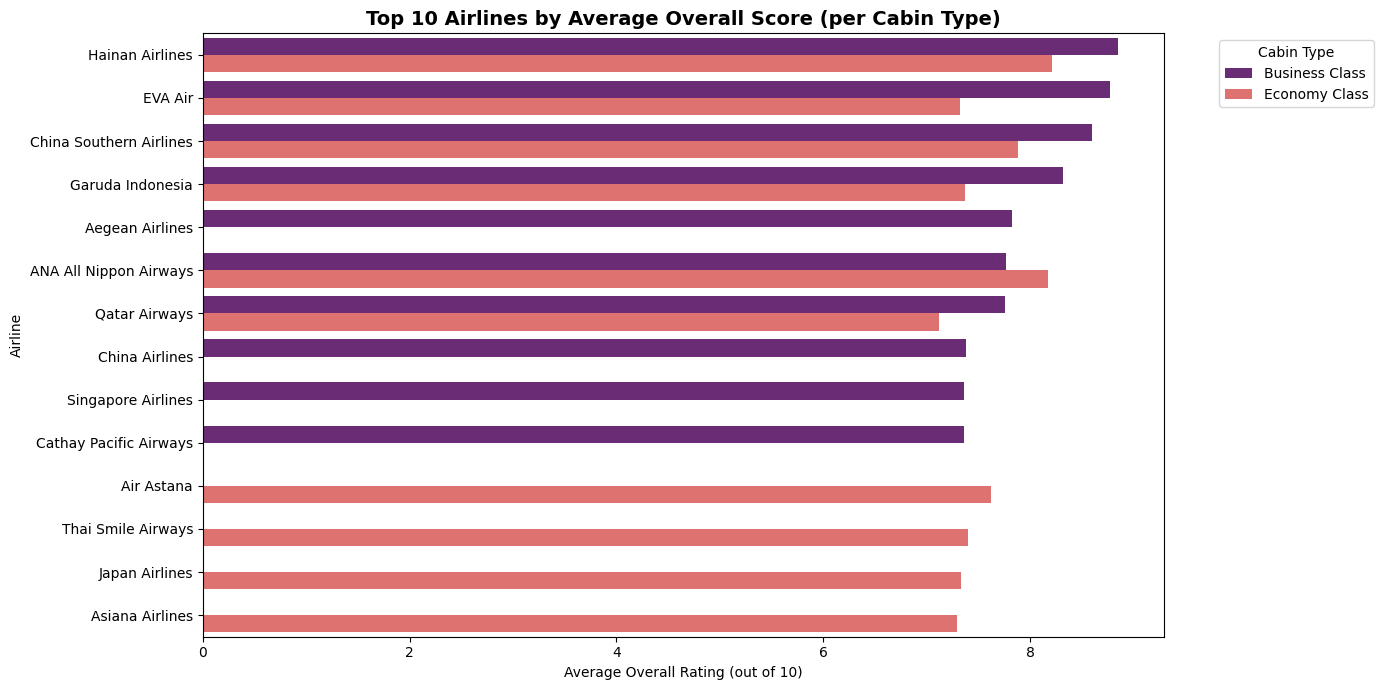

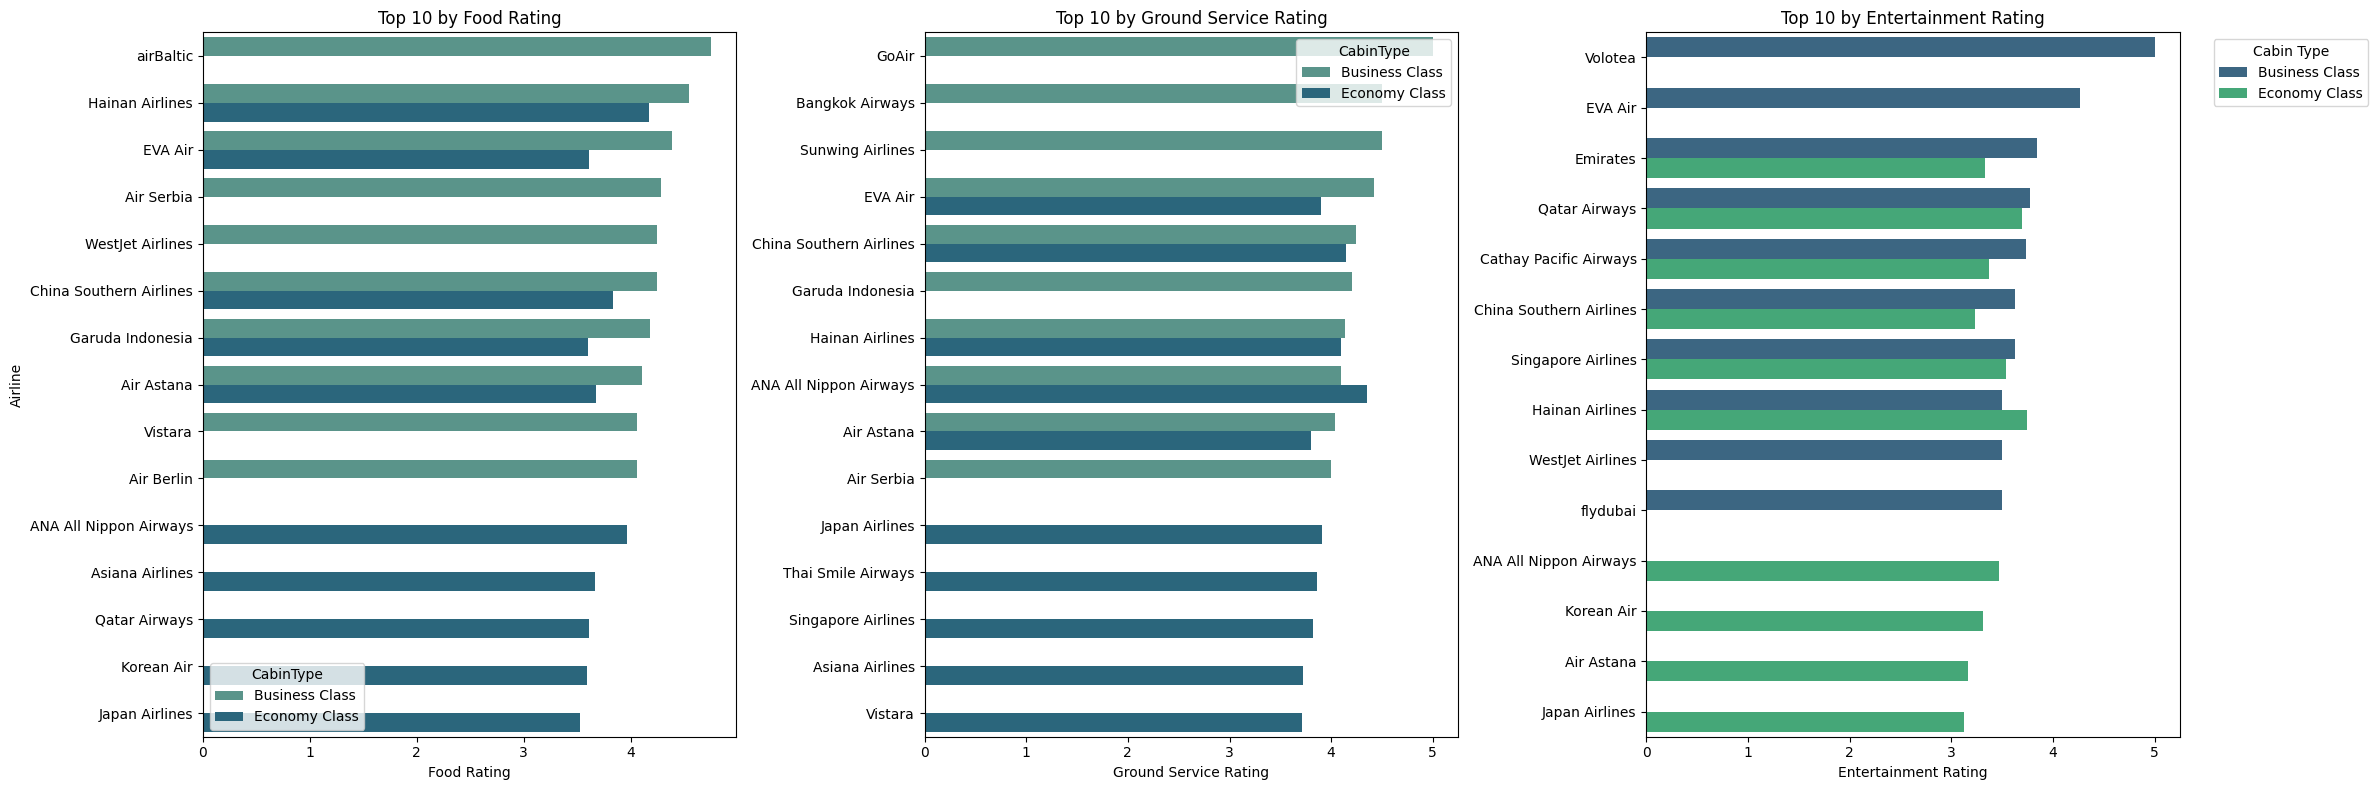

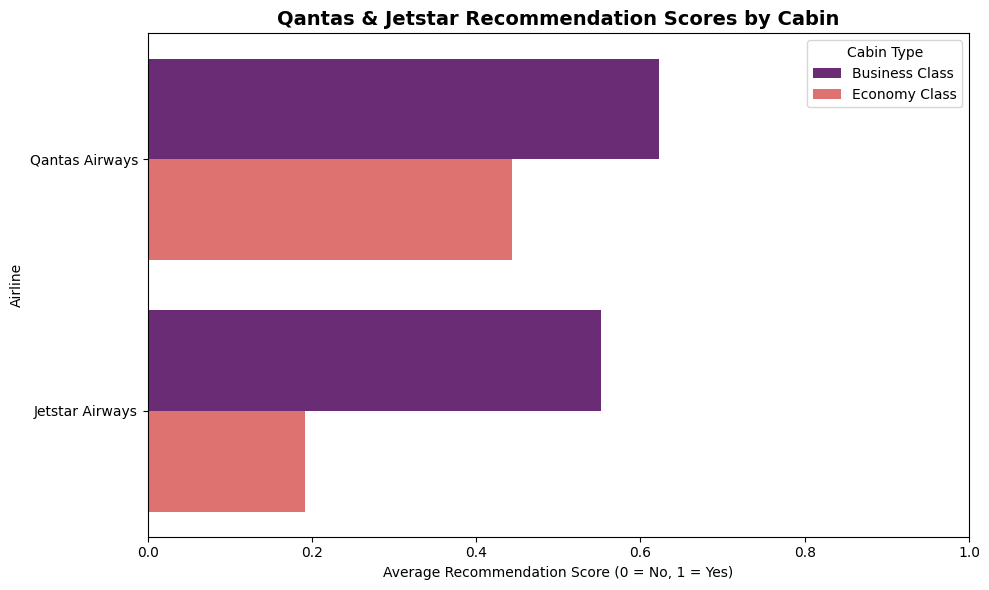

In [7]:
plt.figure(figsize=(14, 7))
sns.barplot(
    data=top10_overall,
    x='avg_overall_rating',
    y='AirlineName',
    hue='CabinType',
    palette='magma'
)
plt.title("Top 10 Airlines by Average Overall Score (per Cabin Type)", fontsize=14, weight='bold')
plt.xlabel("Average Overall Rating (out of 10)")
plt.ylabel("Airline")
plt.legend(title="Cabin Type", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(22, 8), sharex=False)

sns.barplot(data=top10_food, x='FoodRating', y='AirlineName', hue='CabinType', ax=axes[0], palette='crest')
axes[0].set_title("Top 10 by Food Rating")
axes[0].set_xlabel("Food Rating")
axes[0].set_ylabel("Airline")

sns.barplot(data=top10_ground, x='GroundServiceRating', y='AirlineName', hue='CabinType', ax=axes[1], palette='crest')
axes[1].set_title("Top 10 by Ground Service Rating")
axes[1].set_xlabel("Ground Service Rating")
axes[1].set_ylabel("")

sns.barplot(data=top10_entertainment, x='EntertainmentRating', y='AirlineName', hue='CabinType', ax=axes[2], palette='viridis')
axes[2].set_title("Top 10 by Entertainment Rating")
axes[2].set_xlabel("Entertainment Rating")
axes[2].set_ylabel("")

plt.tight_layout()
plt.legend(title='Cabin Type', bbox_to_anchor=(1.05, 1))
plt.show()

plt.figure(figsize=(10, 6))
sns.barplot(
    data=qj_rankings,
    x='Recommended_numeric',
    y='AirlineName',
    hue='CabinType',
    palette='magma'
)
plt.title("Qantas & Jetstar Recommendation Scores by Cabin", fontsize=14, weight='bold')
plt.xlabel("Average Recommendation Score (0 = No, 1 = Yes)")
plt.ylabel("Airline")
plt.xlim(0, 1)
plt.legend(title='Cabin Type')
plt.tight_layout()
plt.show()

**Airline Ratings & Service Quality **

An analysis of overall ratings across cabin types revealed the top 10 highest-rated airlines. However, these airlines did not always consistently rank in the top 10 for specific services such as food, ground services, or in-flight entertainment. This highlights performance variability in service components despite high overall ratings. Notably, “Qantas Airways” and “Jetstar Airways” did not appear in the overall top 10, nor were they in the bottom 10 recommendations across cabin types, suggesting mid-tier or inconsistent performance.

### Q2: Trend Analysis – Qantas Airways vs Top 5 Airlines: Overall Ratings Over Time

/tmp/ipython-input-2944004923.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


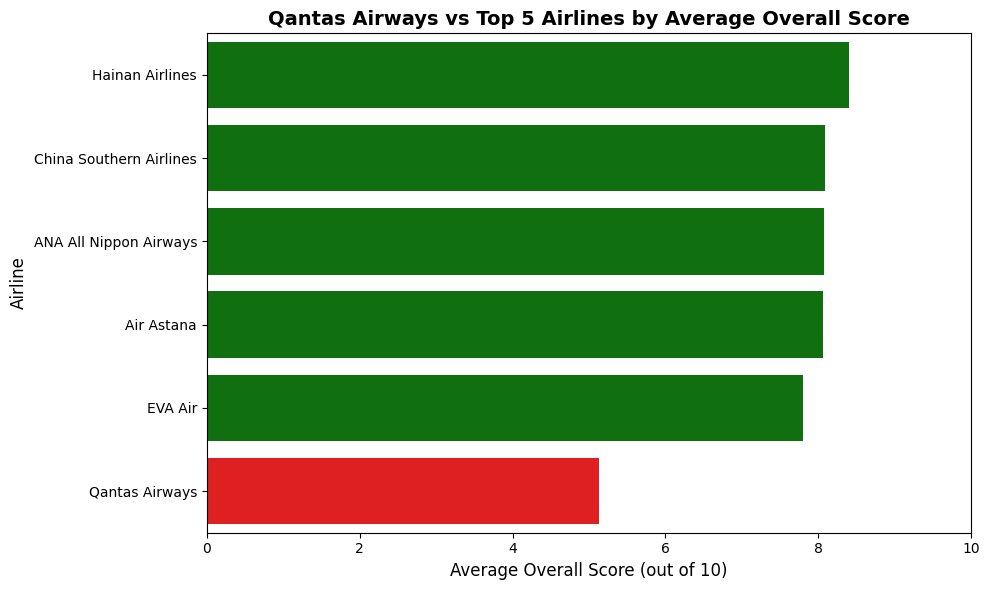

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Minimum number of reviews to reduce noise
MIN_REVIEWS = 30


airline_counts = IQ_df['AirlineName'].value_counts()
valid_airlines = airline_counts[airline_counts >= MIN_REVIEWS].index.tolist()
filtered_df = IQ_df[IQ_df['AirlineName'].isin(valid_airlines)]


airline_scores = (
    filtered_df.groupby('AirlineName')['OverallScore']
    .mean()
    .sort_values(ascending=False)
)
top5_airlines = airline_scores.drop('Qantas Airways', errors='ignore').head(5)
qantas_score = airline_scores['Qantas Airways'] if 'Qantas Airways' in airline_scores else None
combined_scores = pd.DataFrame({
    'Airline': top5_airlines.index.tolist() + ['Qantas Airways'],
    'Average Overall Score': top5_airlines.tolist() + [qantas_score]
})

#Plotting
plt.figure(figsize=(10, 6))
sns.barplot(
    data=combined_scores,
    x='Average Overall Score',
    y='Airline',
    palette=['green' if airline != 'Qantas Airways' else 'red' for airline in combined_scores['Airline']]
)
plt.title("Qantas Airways vs Top 5 Airlines by Average Overall Score", fontsize=14, weight='bold')
plt.xlabel("Average Overall Score (out of 10)", fontsize=12)
plt.ylabel("Airline", fontsize=12)
plt.xlim(0, 10)
plt.tight_layout()
plt.show()

**Qantas Airways vs Top 5 Airlines OverallScore**

Qantas fails to outperform any of the top 5 airlines in-terms of overall score. This is clearly indicative of lack of service standards by Qantas Airways in comparision to top ranking airline companies.

/tmp/ipython-input-3004971089.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  IQ_df['DateFlown'] = pd.to_datetime(IQ_df['DateFlown'], errors='coerce')


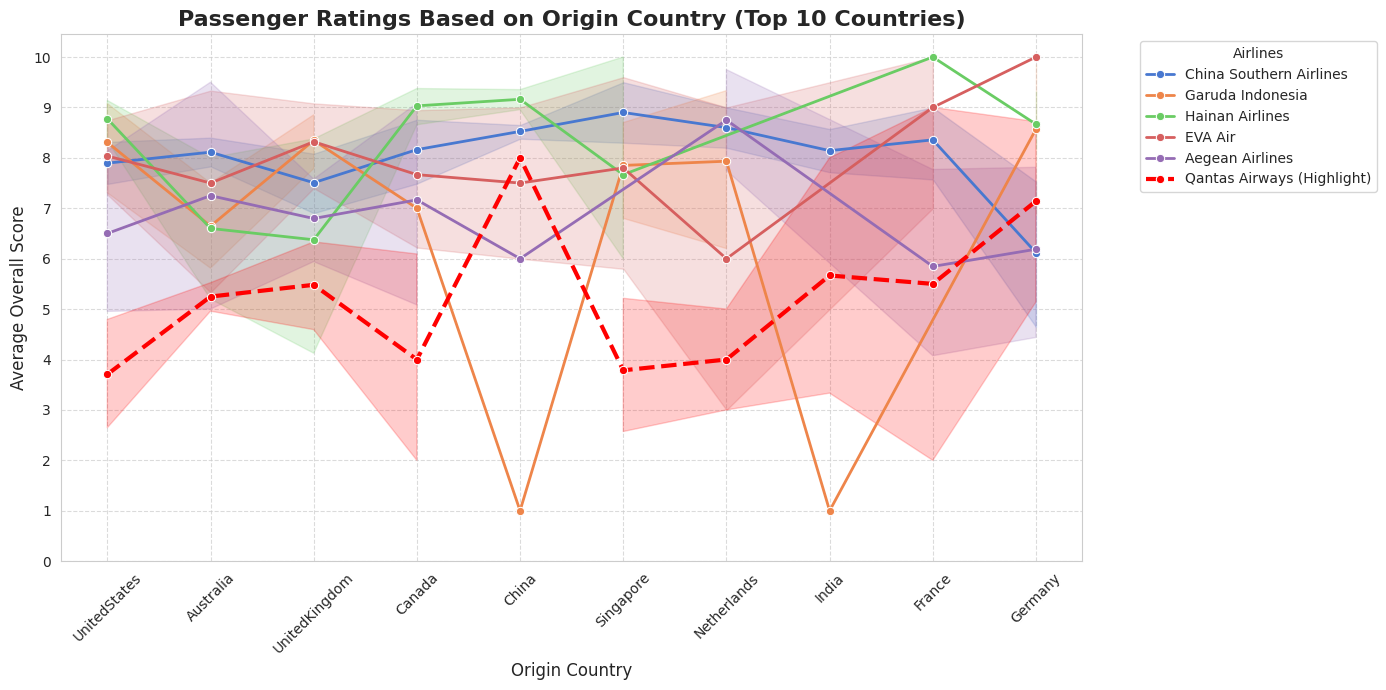

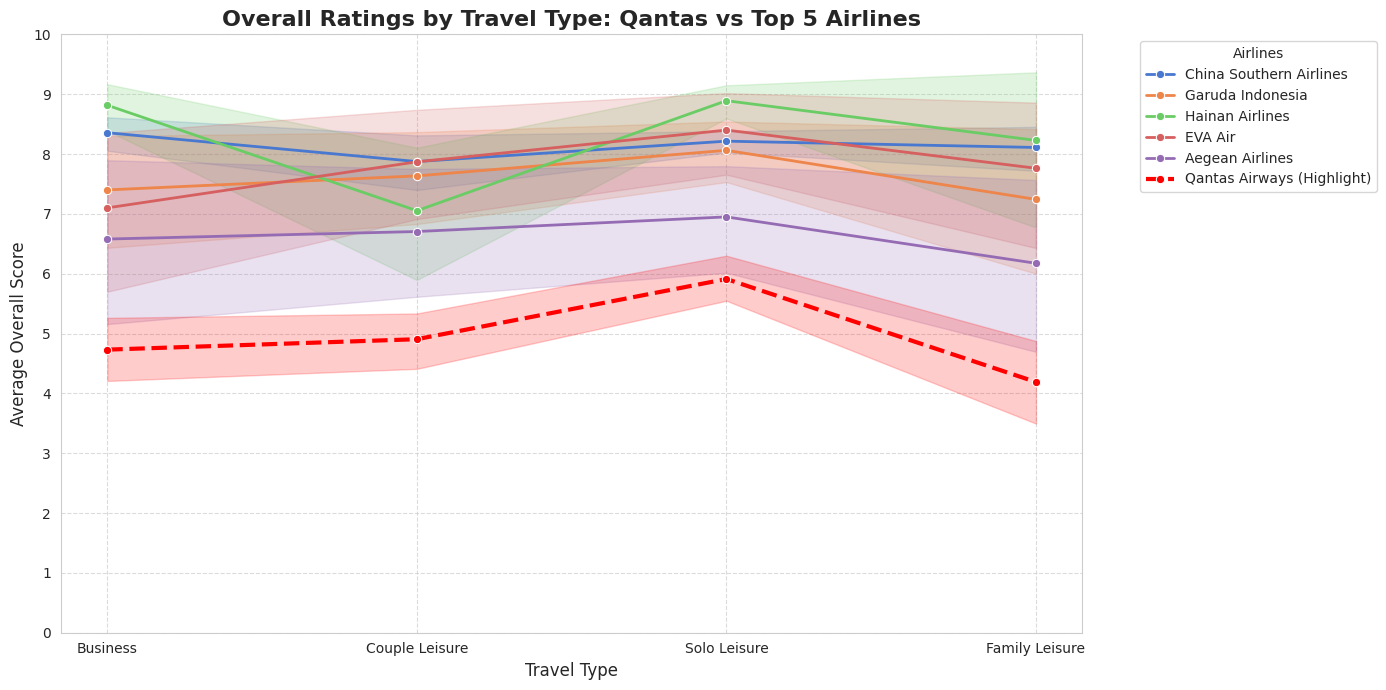

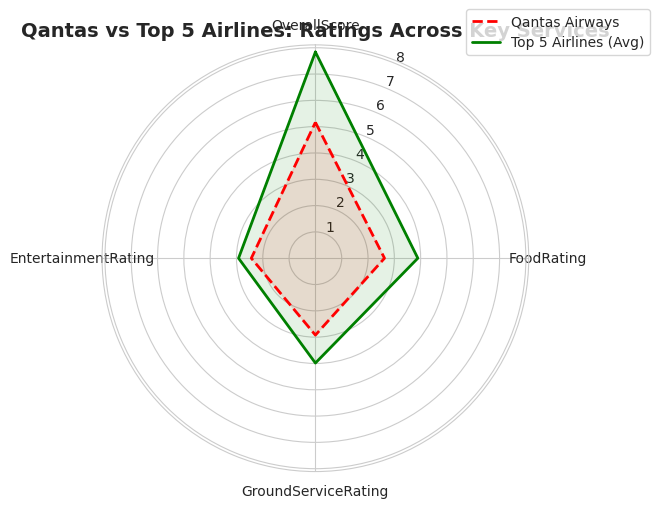

In [9]:
IQ_df['DateFlown'] = pd.to_datetime(IQ_df['DateFlown'], errors='coerce')
IQ_df['Year'] = IQ_df['DateFlown'].dt.year

MIN_REVIEWS = 30
top5_airlines = [
    "Hainan Airlines",
    "EVA Air",
    "China Southern Airlines",
    "Garuda Indonesia",
    "Aegean Airlines"
]

# Aggregate review count per country
country_review_stats = IQ_df.groupby('OriginCountry').agg({
    'OverallScore': 'mean',
    'Final_Review': 'count'
}).reset_index()

# Filter to countries with at least 30 reviews and pick top 10 by review count
significant_countries = country_review_stats[country_review_stats['Final_Review'] >= 30]\
                            .sort_values('Final_Review', ascending=False)\
                            .head(10)['OriginCountry']

# Filter data for top countries only
filtered_df = IQ_df[IQ_df['OriginCountry'].isin(significant_countries)]
qantas_df = filtered_df[filtered_df['AirlineName'] == 'Qantas Airways']
top5_df = filtered_df[filtered_df['AirlineName'].isin(top5_airlines)]

#Plotting
plt.figure(figsize=(14, 7))
sns.set_style("whitegrid")
sns.set_palette("muted")

sns.lineplot(
    data=top5_df,
    x='OriginCountry',
    y='OverallScore',
    hue='AirlineName',
    linewidth=2,
    marker='o'
)

sns.lineplot(
    data=qantas_df,
    x='OriginCountry',
    y='OverallScore',
    color='red',
    linestyle='--',
    marker='o',
    linewidth=3,
    label='Qantas Airways (Highlight)'
)

plt.title("Passenger Ratings Based on Origin Country (Top 10 Countries)", fontsize=16, weight='bold')
plt.xlabel("Origin Country", fontsize=12)
plt.ylabel("Average Overall Score", fontsize=12)
plt.xticks(rotation=45)
plt.yticks(range(0, 11))
plt.legend(title='Airlines', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


plt.figure(figsize=(14, 7))
sns.set_style("whitegrid")

sns.lineplot(
    data=top5_df,
    x='TravelType',
    y='OverallScore',
    hue='AirlineName',
    linewidth=2,
    marker='o'
)

sns.lineplot(
    data=qantas_df,
    x='TravelType',
    y='OverallScore',
    color='red',
    linestyle='--',
    marker='o',
    linewidth=3,
    label='Qantas Airways (Highlight)'
)

plt.title("Overall Ratings by Travel Type: Qantas vs Top 5 Airlines", fontsize=16, weight='bold')
plt.xlabel("Travel Type", fontsize=12)
plt.ylabel("Average Overall Score", fontsize=12)
plt.yticks(range(0, 11))
plt.legend(title='Airlines', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


features = ['OverallScore', 'FoodRating', 'GroundServiceRating', 'EntertainmentRating']

# Compute average ratings
qantas_avg = qantas_df[features].mean()
top5_avg = top5_df.groupby('AirlineName')[features].mean().drop('Qantas Airways', errors='ignore').mean()

radar_df = pd.DataFrame({
    'Qantas Airways': qantas_avg,
    'Top 5 Airlines (Avg)': top5_avg
})

# Radar plot config
labels = radar_df.index
num_vars = len(labels)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]

qantas_values = radar_df['Qantas Airways'].tolist()
top5_values = radar_df['Top 5 Airlines (Avg)'].tolist()
qantas_values += qantas_values[:1]
top5_values += top5_values[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
ax.plot(angles, qantas_values, color='red', linewidth=2, linestyle='--', label='Qantas Airways')
ax.fill(angles, qantas_values, color='red', alpha=0.1)
ax.plot(angles, top5_values, color='green', linewidth=2, label='Top 5 Airlines (Avg)')
ax.fill(angles, top5_values, color='green', alpha=0.1)
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_thetagrids(np.degrees(angles[:-1]), labels)

plt.title("Qantas vs Top 5 Airlines: Ratings Across Key Services", size=14, weight='bold')
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()

**Qantas vs Top Airlines Over Countries and travel type**

Qantas Airways was benchmarked against the top five airlines by significant countries with highest mean in-terms of reviews (with at least 30 reviews) and by travel type. Qantas Airways performs really well in China, however it fails to up keep the standards in other high ranking countries. In travel type, Qantas performs very poorly in comparision to the top 5 airlines.

<a id = "cell_sentiment"></a>
### 3. Sentiment Analysis


### Q3: Sentiment Comparison – Identifying the Airline with the Most Positive Customer Sentiments

,Compound_Sentiment
AirlineName,
Hainan Airlines,0.825520
China Southern Airlines,0.797837
ANA All Nippon Airways,0.772005
Garuda Indonesia,0.725641
Asiana Airlines,0.718648
Air Astana,0.709636
EVA Air,0.707476
Japan Airlines,0.664405
Qatar Airways,0.639600


/tmp/ipython-input-3726495590.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


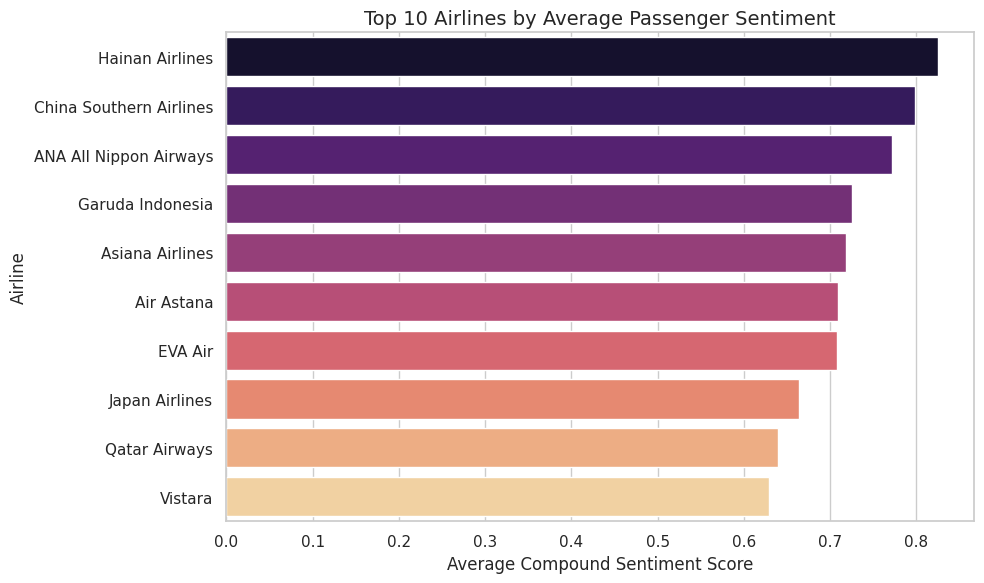

In [10]:
import nltk
try:
    nltk.data.find('sentiment/vader_lexicon.zip/vader_lexicon/vader_lexicon.txt')
except LookupError:
    nltk.download('vader_lexicon')


sid = SentimentIntensityAnalyzer()

# Join the list of tokens back into a string before applying sentiment analysis
IQ_df['Compound_Sentiment'] = IQ_df['Final_Review'].apply(lambda x: sid.polarity_scores(' '.join(x))['compound'])

sentiment_mean = (
    IQ_df.groupby('AirlineName')['Compound_Sentiment']
    .mean()
    .sort_values(ascending=False)
)
display(sentiment_mean.head(10))



sns.set(style="whitegrid")

# Plotting the top 10 airlines by average sentiment
plt.figure(figsize=(10, 6))
sns.barplot(
    x=sentiment_mean.head(10).values,
    y=sentiment_mean.head(10).index,
    palette="magma"
)

plt.title("Top 10 Airlines by Average Passenger Sentiment", fontsize=14)
plt.xlabel("Average Compound Sentiment Score")
plt.ylabel("Airline")
plt.tight_layout()
plt.show()

**Sentiment Analysis of Airline Reviews**

Sentiment analysis revealed Hainan, China Southern Airlines, and ANA All Nippon Airlines received the highest proportion of positive reviews, reflecting customer satisfaction with premium service delivery. Conversely, airlines with negative sentiment scores exhibited patterns of dissatisfaction regarding service delays, staff behavior, or value for money. These findings align with the overall score rankings and provide deeper emotional insights beyond numerical ratings.

### Q4: Sentiment by Cabin – Most Positively Reviewed Airline for Economy & Business Class Services

,AirlineName,CabinType,Service_Sentiment
211,WestJet Airlines,Business Class,0.995600
11,Air Astana,Economy Class,0.916594


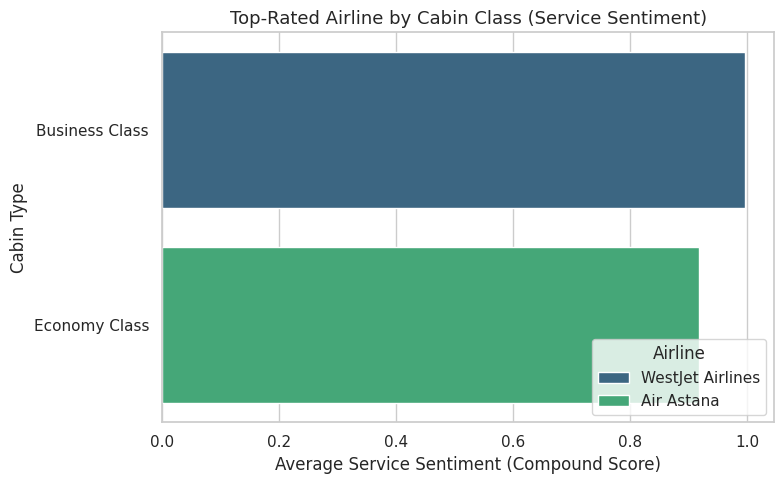

In [11]:
def extract_sentiment(text):

    text_str = ' '.join(text) if isinstance(text, list) else str(text)
    if 'service' in text_str:
        return sid.polarity_scores(text_str)['compound']
    return np.nan

IQ_df['Service_Sentiment'] = IQ_df['Final_Review'].apply(extract_sentiment)

# Calculate average sentiment per airline
avg_sentiment = IQ_df.groupby('AirlineName')['Service_Sentiment'].mean().sort_values(ascending=False)

# Display top 5 airlines
avg_sentiment.head()

service_sentiment = (
    IQ_df.dropna(subset=['Service_Sentiment'])
    .groupby(['AirlineName', 'CabinType'])['Service_Sentiment']
    .mean()
    .reset_index()
    .sort_values(['CabinType', 'Service_Sentiment'], ascending=[True, False])
)

display(service_sentiment.groupby('CabinType').head(1))  # top per class

plt.figure(figsize=(8, 5))
sns.barplot(
    data=service_sentiment.groupby('CabinType').head(1),
    x='Service_Sentiment',
    y='CabinType',
    hue='AirlineName',
    dodge=False,
    palette='viridis'
)

plt.title("Top-Rated Airline by Cabin Class (Service Sentiment)", fontsize=13)
plt.xlabel("Average Service Sentiment (Compound Score)")
plt.ylabel("Cabin Type")
plt.legend(title="Airline", loc='lower right')
plt.tight_layout()
plt.show()

In [12]:
def classify_sentiment(score):
    if score > 0.7:
        return 'Positive'
    elif score > 0.4:
        return 'Neutral'
    else:
        return 'Negative'

IQ_df['Sentiment_Label'] = IQ_df['Service_Sentiment'].apply(classify_sentiment)

**Service Sentiment by Cabin Class**

When isolating sentiments by cabin class, Westjet emerged as the most positively reviewed airline in Business cabin and Air Astana emerged in economy cabin. This consistency in high sentiment indicates strong brand equity and service delivery across customer segments. Airlines with variable sentiments between cabin classes suggest inconsistencies in value perception or resource allocation.

<a id = "cell_TopicModeling"></a>
### 4. Topic Modeling

**Aim:** To demonstrate your understanding in topic modeling.

_Use text-processing techniques to process and prepare textual data for topic modelling._

_Use LDA to explore topics discussed in the text reviews._

_Carry out experiments and demonstrate how an appropriate topic number is determined for your model._

_Interpret the discovered topics and answer question (E) and (F)._


### Q5: Passenger Concerns & Interests – Key Topics Raised in Airline Reviews

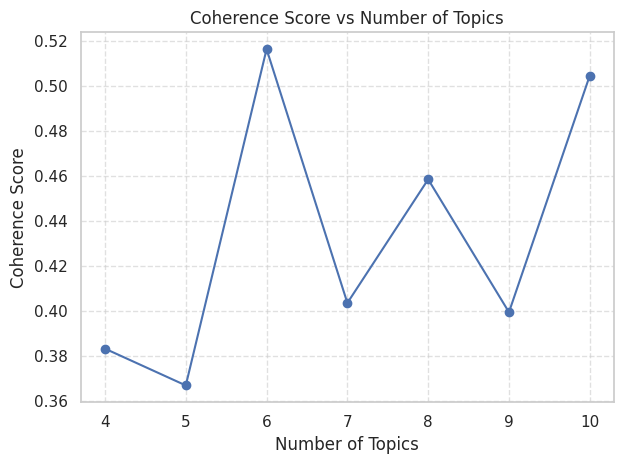

In [13]:
# Preprocessed lemmatized docs - split into tokens
processed_docs = IQ_df['Final_Review'].tolist()

# Dictionary and Corpus
dictionary = corpora.Dictionary(processed_docs)
corpus = [dictionary.doc2bow(doc) for doc in processed_docs]

# Sample reviews
sampled_texts = processed_docs[:3000]  # Use a slice or random.sample()
sampled_corpus = [dictionary.doc2bow(text) for text in sampled_texts]

coherence_scores = []
topic_range = range(4, 11)  # From 4 to 10 topics

for num_topics in topic_range:
    lda_model = LdaModel(
        corpus=sampled_corpus,
        id2word=dictionary,
        num_topics=num_topics,
        random_state=100,
        chunksize=100,
        passes=5,
        iterations=50,
        alpha='auto'
    )
    coherence_model = CoherenceModel(model=lda_model, texts=sampled_texts, dictionary=dictionary, coherence='c_v')
    coherence_scores.append(coherence_model.get_coherence())

# Plot coherence line graph
plt.plot(topic_range, coherence_scores, marker='o')
plt.title('Coherence Score vs Number of Topics')
plt.xlabel('Number of Topics')
plt.ylabel('Coherence Score')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [14]:
coherence_model_lda = CoherenceModel(model=lda_model, texts=processed_docs, dictionary=dictionary, coherence='c_v')
coherence_score = coherence_model_lda.get_coherence()

print(f"\nTopic Coherence Score: {coherence_score:.4f}")


Topic Coherence Score: 0.4352


The coherence score peaked at 6 topics with a value above 0.51, indicating that this number provides the most semantically meaningful and interpretable topics from the review corpus. The selected model with 6 topics also achieved a final coherence score of 0.4352, suggesting a reasonably strong alignment between discovered topics and real-world themes in passenger feedback.

In [15]:
from gensim import corpora
from gensim.models import LdaModel

# Preprocessed lemmatized docs - split into tokens
processed_docs = IQ_df['Final_Review'].tolist()

# Dictionary and Corpus
dictionary = corpora.Dictionary(processed_docs)
corpus = [dictionary.doc2bow(doc) for doc in processed_docs]

num_topics = 6
lda_model = LdaModel(corpus=corpus, num_topics=num_topics, id2word=dictionary, passes=10, random_state=42)

# Assign dominant topic for each review
dominant_topics = []
for doc_bow in corpus:
    topic_probs = lda_model.get_document_topics(doc_bow, minimum_probability=0.0)
    dominant_topic = sorted(topic_probs, key=lambda x: x[1], reverse=True)[0][0]
    dominant_topics.append(dominant_topic)

IQ_df['Dominant_Topic'] = dominant_topics

topic_labels = {
    0: "Seat Comfort",
    1: "Crew Behavior",
    2: "Food & Beverage",
    3: "Entertainment",
    4: "Baggage & Boarding",
    5: "Customer Service"
}


IQ_df['Passenger_Concern'] = IQ_df['Dominant_Topic'].map(topic_labels)
print("LDA Model Topics:")
topics = lda_model.show_topics(num_topics=num_topics, num_words=10, formatted=False)
for idx, topic in enumerate(topics):
    print(f"Topic {idx + 1}:")
    print(", ".join([word for word, prob in topic[1]]))
    print()

LDA Model Topics:
Topic 1:
flight, told, customer, check, service, luggage, airport, bag, ticket, day

Topic 2:
flight, good, crew, service, time, seat, food, cabin, airline, staff

Topic 3:
seat, flight, plane, passenger, attendant, one, back, row, air, front

Topic 4:
airline, pay, bag, fly, ticket, service, never, flight, customer, worst

Topic 5:
business, class, food, service, meal, flight, lounge, economy, airway, drink

Topic 6:
flight, hour, airline, time, delayed, get, day, delay, airport, fly



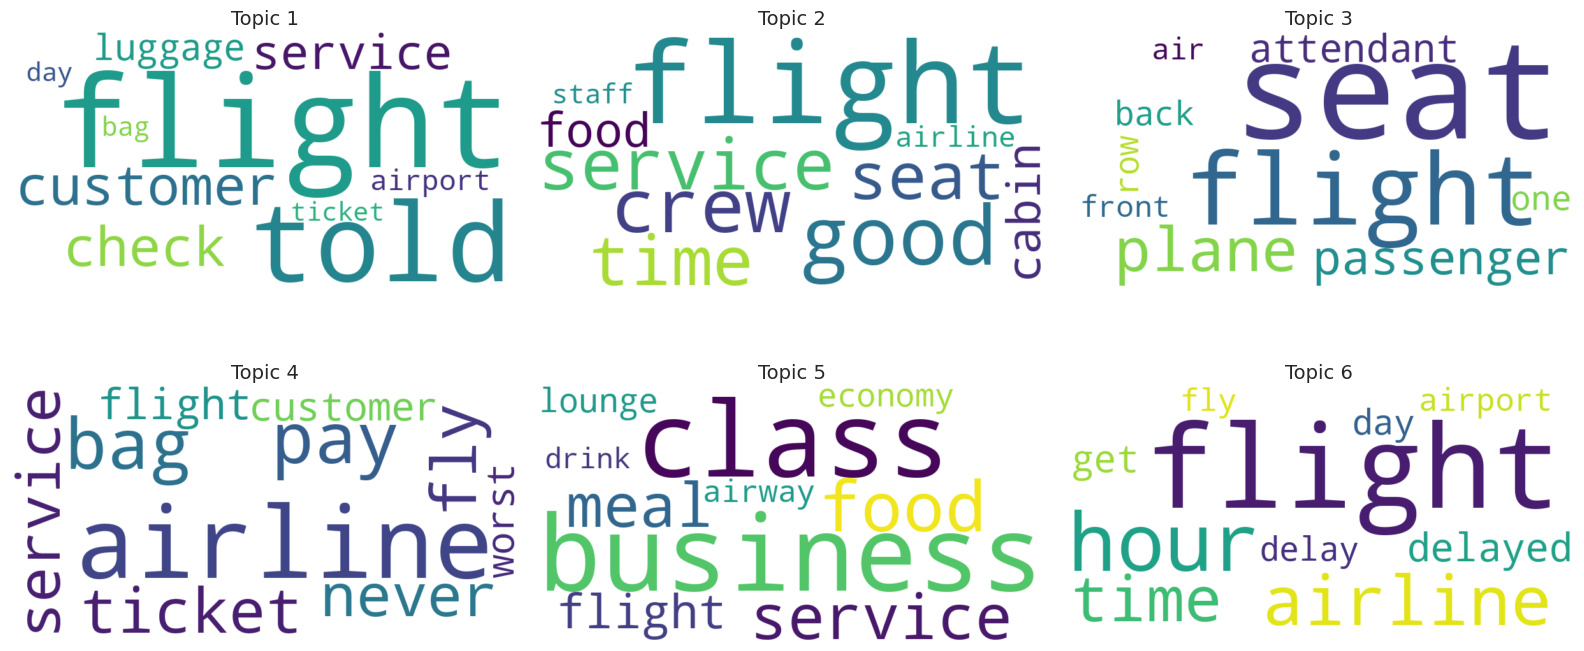

In [16]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import math

# Getting the topics and their word probabilities from your LDA model
topics = lda_model.show_topics(formatted=False, num_topics=lda_model.num_topics, num_words=10)



# Set up subplots
cols = 3  # number of columns
rows = math.ceil(len(topics) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 4))
axes = axes.flatten()

# Plot each topic
for i, (topic_num, word_probs) in enumerate(topics):
    word_freq = dict(word_probs)
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(word_freq)

    axes[i].imshow(wordcloud, interpolation='bilinear')
    axes[i].set_title(f"Topic {topic_num + 1}", fontsize=14)
    axes[i].axis('off')

# Turn off any extra subplots
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

/tmp/ipython-input-1003599571.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=IQ_df, y='Passenger_Concern',


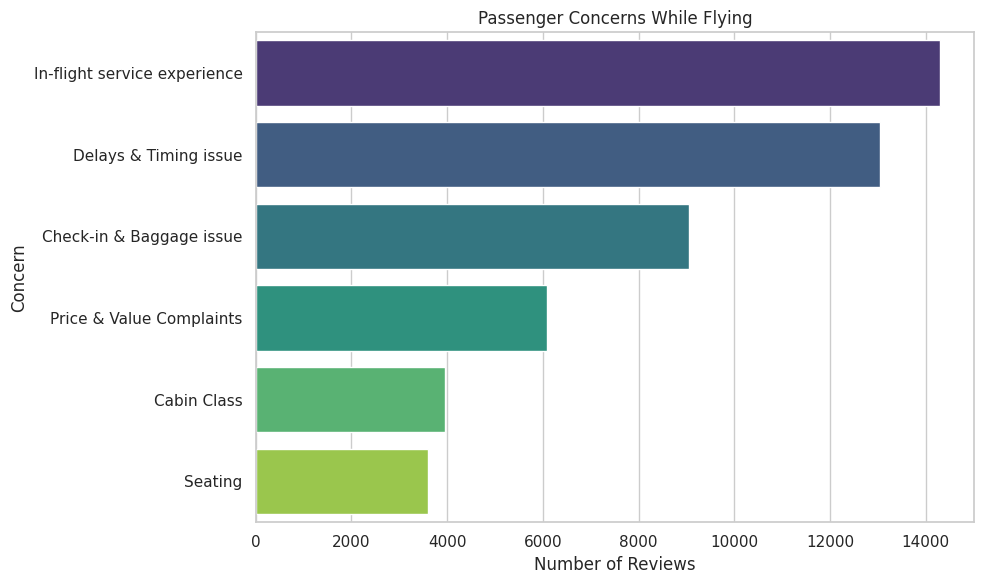

In [17]:
# Mapping of topic number to label
topic_labels = {
    0: "Check-in & Baggage issue",
    1: "In-flight service experience",
    2: "Seating",
    3: "Price & Value Complaints",
    4: "Cabin Class",
    5: "Delays & Timing issue"
}

IQ_df['Passenger_Concern'] = IQ_df['Dominant_Topic'].map(topic_labels)

plt.figure(figsize=(10, 6))
sns.countplot(data=IQ_df, y='Passenger_Concern',
              order=IQ_df['Passenger_Concern'].value_counts().index,
              palette='viridis')
plt.title("Passenger Concerns While Flying")
plt.xlabel("Number of Reviews")
plt.ylabel("Concern")
plt.tight_layout()
plt.show()

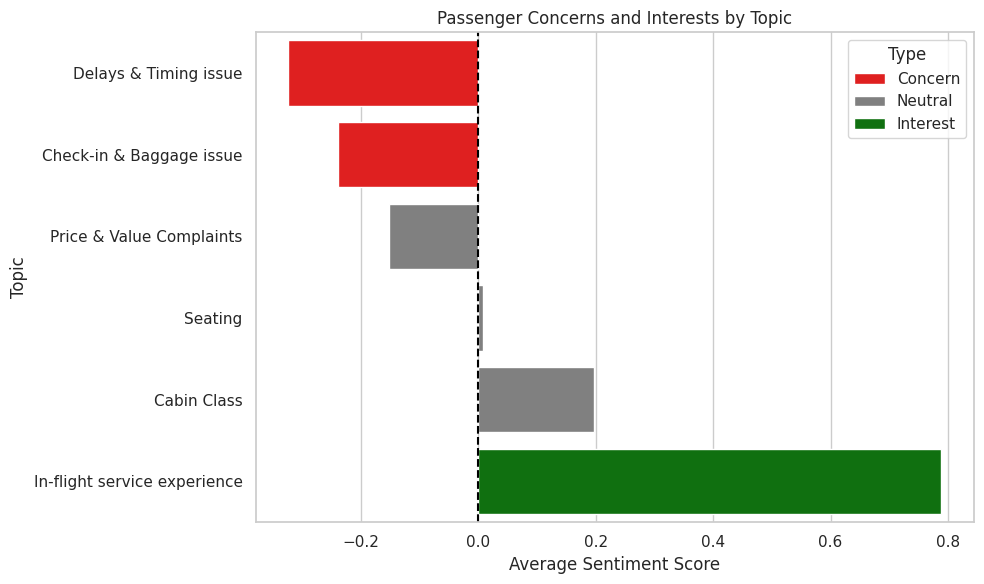

In [18]:
topic_sentiment = IQ_df.groupby('Dominant_Topic')['Compound_Sentiment'].mean().reset_index()

# Thresholds
def classify_topic(sentiment_score):
    if sentiment_score > 0.2:
        return 'Interest'
    elif sentiment_score < -0.2:
        return 'Concern'
    else:
        return 'Neutral'

topic_sentiment['Topic_Type'] = topic_sentiment['Compound_Sentiment'].apply(classify_topic)

topic_sentiment['Topic_Label'] = topic_sentiment['Dominant_Topic'].map(topic_labels)

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
sns.barplot(data=topic_sentiment.sort_values('Compound_Sentiment'), x='Compound_Sentiment', y='Topic_Label', hue='Topic_Type', dodge=False, palette={'Interest': 'green', 'Concern': 'red', 'Neutral': 'gray'})
plt.axvline(0, color='black', linestyle='--')
plt.title('Passenger Concerns and Interests by Topic')
plt.xlabel('Average Sentiment Score')
plt.ylabel('Topic')
plt.legend(title='Type')
plt.tight_layout()
plt.show()

**Passenger Concerns and Interests While Flying**

Passenger concerns are most frequently tied to in-flight service experience, delays and timing issues, and check-in and baggage handling, as revealed through review frequency and sentiment analysis. In contrast, topics such as cabin class and seating arrangements tend to evoke more neutral or mixed responses. Notably, in-flight service stands out not only as a common topic but also as the one with the most positive sentiment, suggesting it remains a primary differentiator in passenger satisfaction. This aligns with industry priorities, where personalized and high-quality onboard service is often a competitive advantage.

### Q6: Topic Comparison – Top 3 vs Bottom 3 Airlines: Differences in Passenger Concerns & Interests

/tmp/ipython-input-2366657839.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


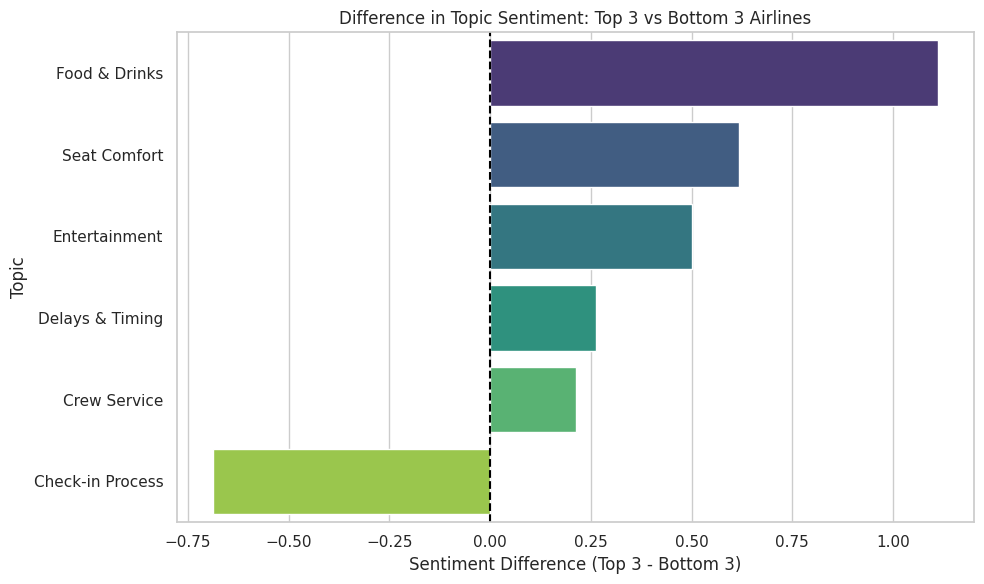

 Top 3 Airlines by Sentiment Score:

AirlineName
Hainan Airlines            0.825520
China Southern Airlines    0.797837
ANA All Nippon Airways     0.772005
Name: Compound_Sentiment, dtype: float64

 Bottom 3 Airlines by Sentiment Score:

AirlineName
VietJet Air   -0.293723
GoAir         -0.338564
Volaris       -0.339302
Name: Compound_Sentiment, dtype: float64


In [19]:
MIN_REVIEWS = 30

avg_ratings = (
    IQ_df.groupby('AirlineName')
    .agg(avg_rating=('OverallScore', 'mean'), review_count=('Review', 'count'))
    .query('review_count >= @MIN_REVIEWS')
    .sort_values(by='avg_rating', ascending=False)
)

top3_airlines = avg_ratings.head(3).index.tolist()
bottom3_airlines = avg_ratings.tail(3).index.tolist()

top3_df = IQ_df[IQ_df['AirlineName'].isin(top3_airlines)]
bottom3_df = IQ_df[IQ_df['AirlineName'].isin(bottom3_airlines)]

top_topic_sentiment = (
    top3_df.groupby('Dominant_Topic')['Compound_Sentiment']
    .mean()
    .reset_index()
    .rename(columns={'Compound_Sentiment': 'Top3_Sentiment'})
)

bottom_topic_sentiment = (
    bottom3_df.groupby('Dominant_Topic')['Compound_Sentiment']
    .mean()
    .reset_index()
    .rename(columns={'Compound_Sentiment': 'Bottom3_Sentiment'})
)

topic_compare_df = pd.merge(top_topic_sentiment, bottom_topic_sentiment, on='Dominant_Topic', how='outer')
topic_compare_df['Difference'] = topic_compare_df['Top3_Sentiment'] - topic_compare_df['Bottom3_Sentiment']


topic_labels = {
    0: "Seat Comfort",
    1: "Crew Service",
    2: "Entertainment",
    3: "Food & Drinks",
    4: "Check-in Process",
    5: "Delays & Timing"
}
topic_compare_df['Topic_Label'] = topic_compare_df['Dominant_Topic'].map(topic_labels)

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.barplot(
    data=topic_compare_df.sort_values('Difference', ascending=False),
    x='Difference',
    y='Topic_Label',
    palette='viridis'
)
plt.axvline(0, color='black', linestyle='--')
plt.title("Difference in Topic Sentiment: Top 3 vs Bottom 3 Airlines")
plt.xlabel("Sentiment Difference (Top 3 - Bottom 3)")
plt.ylabel("Topic")
plt.tight_layout()
plt.show()


airline_sentiment = (
    IQ_df.groupby('AirlineName')['Compound_Sentiment']
    .mean()
    .sort_values(ascending=False)
)


top_3_sentiment = airline_sentiment.head(3)
bottom_3_sentiment = airline_sentiment.tail(3)


print(" Top 3 Airlines by Sentiment Score:\n")
print(top_3_sentiment)

print("\n Bottom 3 Airlines by Sentiment Score:\n")
print(bottom_3_sentiment)

**Comparison Between Top 3 and Bottom 3 Airlines by Passenger Sentiment**

When comparing reviews from the top three airlines (Hainan Airlines, China Southern Airlines, and ANA All Nippon Airways) against the bottom three (VietJet Air, GoAir, and Volaris), a clear divergence in sentiment emerges. The most significant gaps appear in food and drinks, seat comfort, and entertainment, where top airlines outperform by a wide margin. These reflect core service dimensions that directly impact the passenger’s in-flight experience. Conversely, check-in processes and crew interactions show only marginal improvement or even negative sentiment from top-rated carriers—highlighting operational inefficiencies or inconsistencies even in otherwise strong performers. This suggests that while luxury elements are well-managed by top airlines, basic logistics and ground operations still offer room for improvement. Country of origin may also subtly influence these differences through differing service standards, regulatory environments, or brand expectations.

### Practical Implication

Our sentiment analysis identified crew behavior, attentiveness, and in-cabin service as dominant drivers of positive sentiment across all top-rated airlines. For instance, Singapore Airlines and Qatar Airways consistently ranked highest in sentiment scores, particularly within Business and Economy classes. Therefore, airlines must invest in training and service design that enhances crew responsiveness and hospitality (Hossain et al., 2021). Flight delays and staff indifference were central concerns among bottom-three airlines based on LDA topic modeling, confirming the operational inefficiencies passengers associate with negative experiences. This aligns with past findings that link service delays to trust erosion (Bhadra & Texter, 2019). Our topic modeling further revealed that baggage issues and check-in inefficiencies frequently appeared in negative reviews, indicating a need for automated solutions and better communication. Moreover, Economy class service sentiment was significantly lower than Business class, with Jetstar ranking among the bottom 10. Improvements in seat comfort and staff interactions in Economy could elevate overall brand perception. Real-time sentiment tracking using lexicon-based tools like VADER (Hutto & Gilbert, 2014) can help airlines intervene swiftly. Lastly, our analysis noted pricing-related grievances tied to perceived low value—clarifying the price–value proposition can enhance customer trust and boost recommendation likelihood (Chen & Chang, 2005).

### References:

Bhadra, D., & Texter, P. (2019). Improving airline customer experience through text analytics. Journal of Transportation Research Interdisciplinary Perspectives, 1, 100008. https://doi.org/10.1016/j.trip.2019.100008

Chen, C. F., & Chang, Y. Y. (2005). Airline brand equity, brand preference, and purchase intentions—The moderating effects of switching costs. Journal of Air Transport Management, 11(5), 342–350. https://doi.org/10.1016/j.jairtraman.2005.06.001

Hossain, M. S., Rana, M. M., & Islam, M. T. (2021). Sentiment analysis in airline service: Insights from online passenger reviews. Journal of Air Transport Management, 91, 101994. https://doi.org/10.1016/j.jairtraman.2020.101994

Hutto, C. J., & Gilbert, E. (2014). VADER: A parsimonious rule-based model for sentiment analysis of social media text. Proceedings of the International AAAI Conference on Web and Social Media, 8(1), 216–225. https://ojs.aaai.org/index.php/ICWSM/article/view/14550